In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


# Import all imp library

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, random, os
import torch
import torch.nn as nn
from transformers import AutoTokenizer
import wandb
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')

SEED = 42
def seed_add(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_add()

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
gpu = torch.cuda.device_count()
print(f'Device: {device}, Number of GPU: {gpu}')

Device: cpu, Number of GPU: 0


# Load Data

In [3]:
train_df = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
test_df = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")


# EDA

In [4]:
print(f'Train shape: {train_df.shape}, Test Shape: {test_df.shape}')
print(f'Train Columns {list(train_df.columns)}')
print(f'Test Columns: {list(test_df.columns)}')
print("Null Values")
print(f'Train: {train_df.isnull().sum().sum()}')
print(f'Test: {test_df.isnull().sum().sum()}')

print(f'Answer Ditribution: {train_df["answer"].value_counts().sort_index()}')

train_df.head()

Train shape: (2000, 8), Test Shape: (500, 7)
Train Columns ['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer']
Test Columns: ['id', 'prompt', 'A', 'B', 'C', 'D', 'E']
Null Values
Train: 0
Test: 0
Answer Ditribution: answer
A    369
B    490
C    459
D    358
E    324
Name: count, dtype: int64


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


In [5]:
OPTION_COLS = ['A', 'B', 'C', 'D', 'E']

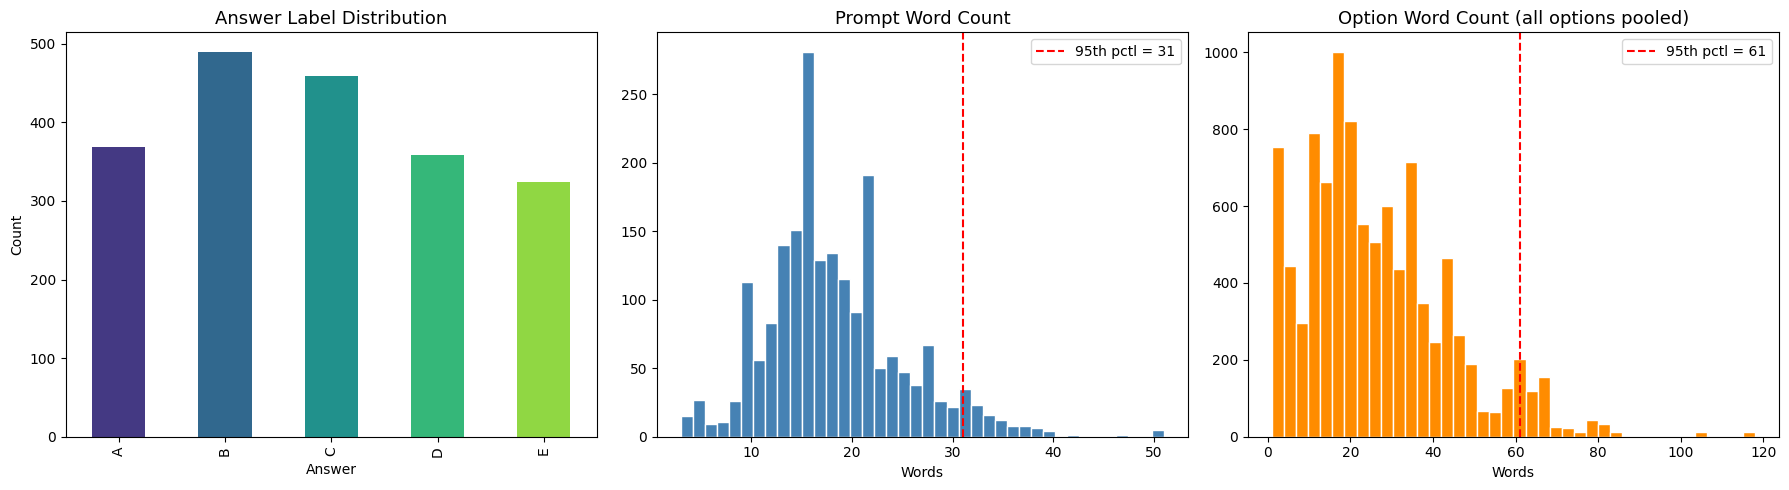

Prompt words — mean: 18.1, 95th: 31, max: 51
Option words — mean: 26.3, 95th: 61, max: 118

→ A max_length of 256 tokens should comfortably cover 95%+ of (prompt + option) pairs.


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. answer distribution
colors = sns.color_palette('viridis', 5)
train_df['answer'].value_counts().sort_index().plot.bar(ax=axes[0], color=colors)
axes[0].set_title('Answer Label Distribution', fontsize=13)
axes[0].set_xlabel('Answer')
axes[0].set_ylabel('Count')

# 2. prompt word-count distribution
prompt_wc = train_df['prompt'].str.split().str.len()
axes[1].hist(prompt_wc, bins=40, color='steelblue', edgecolor='white')
axes[1].axvline(prompt_wc.quantile(0.95), color='red', ls='--', label=f'95th pctl = {prompt_wc.quantile(0.95):.0f}')
axes[1].set_title('Prompt Word Count', fontsize=13)
axes[1].set_xlabel('Words')
axes[1].legend()

# 3. option word-count distribution (all options combined)
option_wc = pd.concat([train_df[c].str.split().str.len() for c in OPTION_COLS])
axes[2].hist(option_wc, bins=40, color='darkorange', edgecolor='white')
axes[2].axvline(option_wc.quantile(0.95), color='red', ls='--', label=f'95th pctl = {option_wc.quantile(0.95):.0f}')
axes[2].set_title('Option Word Count (all options pooled)', fontsize=13)
axes[2].set_xlabel('Words')
axes[2].legend()

plt.tight_layout()
plt.show()

# token-budget estimation
print(f'Prompt words — mean: {prompt_wc.mean():.1f}, 95th: {prompt_wc.quantile(0.95):.0f}, max: {prompt_wc.max()}')
print(f'Option words — mean: {option_wc.mean():.1f}, 95th: {option_wc.quantile(0.95):.0f}, max: {option_wc.max()}')
print('\n→ A max_length of 256 tokens should comfortably cover 95%+ of (prompt + option) pairs.')

# Preprocessing

In [7]:
wandb.login()

wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:

  2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.
wandb: Paste your API key and hit enter:

  ········


wandb: ERROR Invalid API key: API key must have 40+ characters, has 36.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:

...

  2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.
wandb: Paste your API key and hit enter:

  ········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 23f3003059 (23f3003059-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [9]:
# Built From Scratch Model
train_df["combined_options"] = (
    train_df["prompt"] + " " +
    train_df["A"] + " " +
    train_df["B"] + " " +
    train_df["C"] + " " +
    train_df["D"] + " " +
    train_df["E"] 
)

label_encoder = LabelEncoder()
labels = label_encoder.fit_transform(train_df["answer"])

X_train, X_test, y_train, y_test = train_test_split(
    train_df["combined_options"],
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)